# Análisis exploratorio de datos sobre el dataset UCI Cleveland Heart Disease.
### Autor: Leonardo Aldair Orozco Oviedo
### Ciclo: Noveno ciclo de Computación


## 1. Ingesta y descripción del conjunto


### 1.1. Ingesta


Se importa el conjunto Heart Disease mediante `fetch_ucirepo(id=45)`, siguiendo la guía del repositorio oficial [1]. La publicación introductoria describe la muestra de referencia de Cleveland y las variables clínicas y de las pruebas utilizadas [2]. La comprobación de estructura y valores se realiza sobre el archivo efectivamente importado.


In [1]:
import platform
from importlib.metadata import version


import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LinearRegression
from ucimlrepo import fetch_ucirepo

sns.set_style("whitegrid")


In [2]:
dataset_base = fetch_ucirepo(id=45)


X = dataset_base.data.features
y = dataset_base.data.targets


df = pd.concat([X, y], axis=1)


### 1.2. Estructura del conjunto


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


### 1.3. Descripción de las variables


La identificación distingue continua, discreta y categórica a partir del significado de cada atributo documentado [1], [2]. Se contrasta después la forma de registro y la compatibilidad de sus valores con los códigos o conteos admitidos. La presencia de enteros o decimales no determina por sí sola la escala de medición.


In [4]:
tipos_documentados = {
    "age": "Continua", "sex": "Categórica", "cp": "Categórica",
    "trestbps": "Continua", "chol": "Continua", "fbs": "Categórica",
    "restecg": "Categórica", "thalach": "Continua", "exang": "Categórica",
    "oldpeak": "Continua", "slope": "Categórica", "ca": "Discreta",
    "thal": "Categórica", "num": "Categórica",
}
codigos_documentados = {
    "sex": {0, 1}, "cp": {1, 2, 3, 4}, "fbs": {0, 1},
    "restecg": {0, 1, 2}, "exang": {0, 1}, "slope": {1, 2, 3},
    "thal": {3, 6, 7}, "num": {0, 1, 2, 3, 4},
}


def es_entero(serie):
    """True si todos los valores observados son enteros; None si no hay datos."""
    valores = pd.to_numeric(serie.dropna(), errors="raise")
    if valores.empty:
        return None
    if not np.isfinite(valores).all():
        raise ValueError("Se requieren valores numéricos finitos")
    return bool((valores % 1 == 0).all())


def verificar_categorica(nombre, serie):
    """Verifica códigos de una categoría documentada; no la infiere por cardinalidad."""
    if nombre not in codigos_documentados:
        return None
    valores = serie.dropna()
    return bool(valores.isin(codigos_documentados[nombre]).all()) if len(valores) else None


def clasificar_entera(nombre, entero, categoria_valida):
    """Distingue cantidades de códigos enteros según su definición documental."""
    if entero is None:
        return "Sin datos"
    if not entero:
        return "Contiene decimales"
    if tipos_documentados[nombre] == "Categórica":
        return "Entera categórica" if categoria_valida else "Entera categórica: revisar códigos"
    return "Entera cuantitativa"

def identificar_variable(nombre, serie):
    """Encadena ambas comprobaciones y las contrasta con el tipo documentado."""
    entero = es_entero(serie)
    categoria_valida = verificar_categorica(nombre, serie)
    tipo = tipos_documentados[nombre]
    identificacion = clasificar_entera(nombre, entero, categoria_valida)
    compatible = categoria_valida if tipo == "Categórica" else (
        bool(entero and serie.dropna().between(0, 3).all()) if tipo == "Discreta"
        else (True if entero is not None else None))
    if compatible is False:
        print(f"AVISO: {nombre} contiene valores incompatibles con su definición documental.")
    elif compatible is None:
        print(f"AVISO: {nombre} no tiene datos suficientes para esta verificación.")
    return {
        "variable": nombre,
        "identificacion_del_registro": identificacion,
        "tipo_documentado": tipo,
    }


verificacion_diccionario = pd.DataFrame([
    identificar_variable(nombre, df[nombre]) for nombre in tipos_documentados
])
print(verificacion_diccionario.to_string(index=False))


variable identificacion_del_registro tipo_documentado
     age         Entera cuantitativa         Continua
     sex           Entera categórica       Categórica
      cp           Entera categórica       Categórica
trestbps         Entera cuantitativa         Continua
    chol         Entera cuantitativa         Continua
     fbs           Entera categórica       Categórica
 restecg           Entera categórica       Categórica
 thalach         Entera cuantitativa         Continua
   exang           Entera categórica       Categórica
 oldpeak          Contiene decimales         Continua
   slope           Entera categórica       Categórica
      ca         Entera cuantitativa         Discreta
    thal           Entera categórica       Categórica
     num           Entera categórica       Categórica


El diccionario integra las definiciones de UCI y de la publicación original [1], [2] con la comprobación precedente de los valores. Los rangos de las magnitudes describen el archivo Cleveland verificado; los códigos y el dominio de `ca` proceden de la documentación.

**Variables predictoras**

| # | Columna | Descripción | Valores | Tipo de variable |
| --- | --------- | ------------- | --------- | ------------------ |
| 1 | `age` | Edad en años | 29 – 77 | Continua |
| 2 | `sex` | Sexo (1 = masculino; 0 = femenino) | 0, 1 | Categórica |
| 3 | `cp` | Tipo de dolor torácico (1 = angina típica; 2 = angina atípica; 3 = dolor no anginoso; 4 = asintomático) | 1, 2, 3, 4 | Categórica |
| 4 | `trestbps` | Presión arterial en reposo al ingreso (mm Hg) | 94 – 200 | Continua |
| 5 | `chol` | Colesterol sérico (mg/dl) | 126 – 564 | Continua |
| 6 | `fbs` | Glucosa en ayunas > 120 mg/dl (1 = verdadero; 0 = falso) | 0, 1 | Categórica |
| 7 | `restecg` | Electrocardiograma en reposo (0 = normal; 1 = anormalidad de la onda ST-T; 2 = hipertrofia ventricular izquierda) | 0, 1, 2 | Categórica |
| 8 | `thalach` | Frecuencia cardíaca máxima alcanzada | 71 – 202 | Continua |
| 9 | `exang` | Angina inducida por ejercicio (1 = sí; 0 = no) | 0, 1 | Categórica |
| 10 | `oldpeak` | Depresión del segmento ST inducida por ejercicio | 0.0 – 6.2 | Continua |
| 11 | `slope` | Pendiente del segmento ST en ejercicio máximo (1 = ascendente; 2 = plana; 3 = descendente) | 1, 2, 3 | Categórica |
| 12 | `ca` | Número de vasos principales coloreados por fluoroscopia | 0, 1, 2, 3 | Discreta |
| 13 | `thal` | Resultado de gammagrafía con talio (3 = normal; 6 = defecto fijo; 7 = defecto reversible) | 3, 6, 7 | Categórica |

**Variable objetivo**

| Columna | Descripción | Valores | Tipo de variable |
| --------- | ------------- | --------- | ------------------ |
| `num` | Diagnóstico según estado angiográfico; 0 = ausencia y 1–4 = presencia de enfermedad | 0, 1, 2, 3, 4 | Categórica |

**Aclaraciones respecto de la documentación.** La ficha oficial de UCI [1] describe `oldpeak` como entero, pero el archivo Cleveland contiene valores con parte decimal, por lo que se mantiene como una magnitud continua. Para `num`, la documentación completa de atributos presenta una definición binaria, mientras que el resumen del repositorio y los datos contienen cinco códigos (0–4); aquí se conserva esa variable categórica original, cuya binarización se aborda más adelante. Las magnitudes `age`, `trestbps`, `chol` y `thalach` están registradas con enteros: esa forma de registro no cambia por sí sola su tratamiento como continuas; `ca`, en cambio, representa un conteo discreto. Finalmente, `thal` se denomina resultado de gammagrafía con talio conforme a la publicación original [2]; «talasemia», presente en algunos trabajos del corpus y en la versión anterior del glosario, no corresponde a ese atributo.


## 2. Valores Duplicados


### 2.1. Detección de registros duplicados


La revisión de registros repetidos tiene un precedente en Sovia et al. [3], quienes consideran coincidencias de características y etiquetas. En este EDA se adopta una comparación de perfiles basada únicamente en las trece predictoras, excluyendo `num`: se localizan las filas con valores idénticos y se contabilizan las repeticiones. Esta adaptación no permite inferir identidad de pacientes ni concordancia de diagnósticos.


In [5]:
predictoras_duplicados = [columna for columna in df.columns if columna != "num"]
filas_duplicadas = df.duplicated(subset=predictoras_duplicados, keep=False)
repeticiones_adicionales = df.duplicated(subset=predictoras_duplicados).sum()

print(f"Filas que participan en perfiles repetidos: {int(filas_duplicadas.sum())}")
print(f"Repeticiones adicionales a la primera aparición: {int(repeticiones_adicionales)}")
if filas_duplicadas.any():
    print("Filas con predictoras idénticas (num excluido de comparación y presentación):")
    print(df.loc[filas_duplicadas, predictoras_duplicados].to_string())


Filas que participan en perfiles repetidos: 0
Repeticiones adicionales a la primera aparición: 0


## 3. Valores ausentes


### 3.1. Localización y cuantificación


Se verifica la existencia de valores ausentes, procedimiento documentado mediante `isna()` en [4]. Se contabilizan los valores faltantes por columna y las filas afectadas, con sus porcentajes respecto del conjunto, y se localizan los registros correspondientes. Estas comprobaciones se aplican a los ausentes reconocidos por la ingesta; un cero presente no se interpreta como un valor faltante.


In [6]:
print("Número de valores nulos: ", df.isnull().sum().sum())


n_registros = len(df)

ausentes = pd.DataFrame({
    "ausentes": df.isnull().sum(),
    "porcentaje": (df.isnull().sum() / n_registros * 100).round(2),
})
ausentes = ausentes[ausentes["ausentes"] > 0]

print()
print(ausentes.to_string())


Número de valores nulos:  6

      ausentes  porcentaje
ca           4        1.32
thal         2        0.66


In [7]:
filas_con_ausentes = df.isnull().any(axis=1)
n_afectadas = int(filas_con_ausentes.sum())

print(f"Filas con al menos un valor ausente: {n_afectadas} "
      f"({n_afectadas / n_registros * 100:.2f}%)")
print(f"Filas completas:                     {n_registros - n_afectadas}")
print()


registros_afectados = df[filas_con_ausentes].copy()
registros_afectados.insert(
    0, "variable_ausente",
    [", ".join(df.columns[df.loc[i].isnull()]) for i in registros_afectados.index],
)
print("Registros afectados por valores ausentes:")
print(registros_afectados.to_string())


Filas con al menos un valor ausente: 6 (1.98%)
Filas completas:                     297

Registros afectados por valores ausentes:
    variable_ausente  age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope   ca  thal  num
87              thal   53    0   3       128   216    0        2      115      0      0.0      1  0.0   NaN    0
166               ca   52    1   3       138   223    0        0      169      0      0.0      1  NaN   3.0    0
192               ca   43    1   4       132   247    1        2      143      1      0.1      2  NaN   7.0    1
266             thal   52    1   4       128   204    1        0      156      1      1.0      2  0.0   NaN    2
287               ca   58    1   2       125   220    0        0      144      0      0.4      2  NaN   7.0    0
302               ca   38    1   3       138   175    0        0      173      0      0.0      1  NaN   3.0    0


## 4. Análisis univariante


El análisis de las cinco variables continuas se centra en dos procedimientos: evaluar normalidad con Shapiro–Wilk y detectar y contabilizar valores atípicos por IQR. Los histogramas y diagramas de caja acompañan la lectura de los resultados; el precedente de histogramas se encuentra en [4]. Se mantiene la mediana como referencia del centro, coherente con el uso de mediana e IQR descrito en [5], y se calculan los cuartiles necesarios para establecer los límites. Las variables categóricas y el conteo `ca` mantienen su descripción por frecuencias, sin extenderles estas pruebas; la presentación de categóricas mediante recuentos y porcentajes está documentada en [5]. Los porcentajes se calculan sobre los valores observados de cada variable, excluyendo ausentes: 299 para `ca`, 301 para `thal` y 303 para las demás.

**Evaluación de normalidad.** Se aplica Shapiro–Wilk exclusivamente a `age`, `trestbps`, `chol`, `thalach` y `oldpeak`. Peng et al. [5] declaran: “The Shapiro-Wilk test was used to assess the normality of continuous variables”; Çakmak et al. [6] también documentan esta prueba para variables continuas. Se adopta $\alpha = 0{,}05$ como umbral exploratorio, acorde con el criterio general de significancia de ambos trabajos [5], [6]; estos pasajes no especifican un umbral distinto para Shapiro–Wilk. Se informan el estadístico $W$ y el valor $p$: si $p < \alpha$ se rechaza la hipótesis de normalidad; en caso contrario no se rechaza, sin afirmar que la normalidad quede demostrada. La elección responde a su propósito y al respaldo del corpus; no se afirma que sea superior a otras pruebas.

Esta evaluación caracteriza cada distribución global y aporta un antecedente exploratorio para elegir el contraste bivariante. No establece la normalidad dentro de cada grupo diagnóstico: la comparación por rangos se fundamenta también por su propósito y por los antecedentes metodológicos desarrollados en §6.

**Detección y contabilización de valores atípicos.** Se utiliza el rango intercuartílico, $IQR = Q_3 - Q_1$, siguiendo el criterio documentado en [7]: se señalan valores menores que $Q_1 - 1{,}5\,IQR$ o mayores que $Q_3 + 1{,}5\,IQR$. Para cada continua se informan límites, número y porcentaje de valores señalados, desglosados por debajo y por encima de los límites. La suma de esos conteos representa valores atípicos por variable, no necesariamente pacientes diferentes. Los diagramas de caja acompañan esta inspección; su uso para explorar valores atípicos tiene un precedente en [8]. Aquí se documenta únicamente la detección, sin decidir todavía el tratamiento de los registros.

**Caso particular de `ca`.** Conforme al diccionario, `ca` registra un número de vasos y su dominio documentado es 0–3 [1], [2]. Estos valores son cantidades enteras propias de un conteo, no el redondeo de una magnitud continua. Por ello se describe mediante frecuencias por valor. En los trabajos que fundamentan la elección de Shapiro–Wilk, la normalidad se evalúa en variables continuas [5], [6]; este EDA mantiene ese alcance. No se contrasta una normal continua exacta para `ca`, cuyo soporte es discreto y limitado: calcular un valor $p$ no respondería una pregunta necesaria para caracterizar este conteo. La exclusión es una decisión de adecuación y propósito, no una consecuencia de baja dispersión ni del umbral $\alpha = 0{,}05$. Se conserva su carácter cuantitativo discreto; su representación por frecuencias no determina la codificación posterior ni garantiza que el modelo admita valores fuera del dominio documentado.


In [8]:
sns.set_style("whitegrid")

ALFA_NORMALIDAD = 0.05

continuas = ["age", "trestbps", "chol", "thalach", "oldpeak"]
variables_por_frecuencias = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]


resultados_univariantes = {}


def describir_continua(columna, unidad=""):
    """Evalúa normalidad y detecta atípicos por IQR; mediana como referencia visual."""
    serie = df[columna].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    inferiores = serie < limite_inf
    superiores = serie > limite_sup
    atipicos = serie[inferiores | superiores]
    mediana = float(serie.median())
    W, p_sw = stats.shapiro(serie)
    conclusion = ("se rechaza la hipótesis de normalidad" if p_sw < ALFA_NORMALIDAD
                  else "no se rechaza la hipótesis de normalidad")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8),
                                   gridspec_kw={"width_ratios": [3, 1]})
    sns.histplot(serie, ax=ax1, color="steelblue", edgecolor="white")
    ax1.axvline(mediana, color="darkgreen", linewidth=1.4,
                label=f"mediana = {mediana:.2f}")
    ax1.set_title(f"Distribución de {columna}")
    ax1.set_xlabel(unidad)
    ax1.set_ylabel("frecuencia")
    ax1.legend(fontsize=9)
    sns.boxplot(y=serie, ax=ax2, color="steelblue", width=0.45, whis=1.5)
    ax2.set_title(f"Atípicos por IQR: {len(atipicos)}")
    ax2.set_ylabel(unidad)
    plt.tight_layout()
    plt.show()


    normalidad = pd.DataFrame([{
        "N": len(serie), "Mediana": f"{mediana:.2f}",
        "W": f"{W:.4f}", "p": f"{p_sw:.2e}",
        "Resultado": "Se rechaza H₀" if p_sw < ALFA_NORMALIDAD else "No se rechaza H₀",
    }])
    deteccion_iqr = pd.DataFrame([{
        "Límite inferior": f"{limite_inf:.2f}",
        "Límite superior": f"{limite_sup:.2f}",
        "Atípicos": f"{len(atipicos)} de {len(serie)} ({len(atipicos) / len(serie) * 100:.2f} %)",
        "Por debajo": int(inferiores.sum()), "Por encima": int(superiores.sum()),
    }])
    estilos = [
        {"selector": "caption", "props": [("text-align", "left"),
            ("font-weight", "bold"), ("padding", "8px 0")]},
        {"selector": "th", "props": [("background-color", "#eef3f7 !important"),
            ("color", "#182531 !important"),
            ("padding", "8px 12px"), ("text-align", "center")]},
        {"selector": "td", "props": [("padding", "8px 12px"),
            ("text-align", "center")]},
    ]
    display(normalidad.style.hide(axis="index").set_table_styles(estilos).set_caption(
        f"Shapiro–Wilk · α = {ALFA_NORMALIDAD:.2f} · H₀: distribución normal · Mediana en {unidad}"))
    display(deteccion_iqr.style.hide(axis="index").set_table_styles(estilos).set_caption(
        f"Detección por IQR · Límites en {unidad}"))

    resultados_univariantes[columna] = {
        "n": len(serie), "unidad": unidad, "mediana": mediana,
        "W": float(W), "p": float(p_sw),
        "limite_inferior": float(limite_inf), "limite_superior": float(limite_sup),
        "atipicos": len(atipicos), "inferiores": int(inferiores.sum()),
        "superiores": int(superiores.sum()),
    }


def describir_frecuencias(columna, etiquetas):
    """Diagrama de barras y frecuencias de categorías o valores de un conteo."""
    conteo = df[columna].value_counts().sort_index()
    porcentaje = conteo / conteo.sum() * 100

    plt.figure(figsize=(7, 3.4))
    ejes = sns.barplot(x=[etiquetas[int(k)] for k in conteo.index],
                       y=conteo.values, color="steelblue")
    for i, v in enumerate(conteo.values):
        ejes.text(i, v + 2, f"{v}\n{porcentaje.values[i]:.1f} %",
                  ha="center", fontsize=9)
    ejes.set_title(f"Distribución de {columna}")
    ejes.set_ylabel("frecuencia")
    ejes.set_ylim(0, conteo.max() * 1.2)
    plt.tight_layout()
    plt.show()

    resumen = pd.DataFrame({
        "valor_o_categoria": [etiquetas[int(k)] for k in conteo.index],
        "frecuencia": conteo.values,
        "porcentaje": porcentaje.round(1).values,
    })
    print(f"Valores observados: {int(conteo.sum())}; porcentajes calculados sobre ese total.")
    print(resumen.to_string(index=False))


### 4.1. age - edad


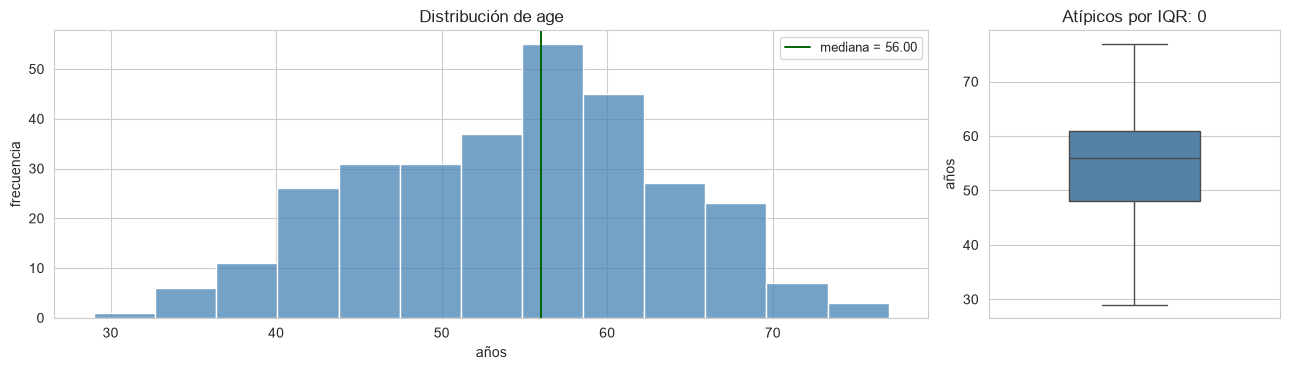

N,Mediana,W,p,Resultado
303,56.00,0.9865,6.07e-03,Se rechaza H₀


Límite inferior,Límite superior,Atípicos,Por debajo,Por encima
28.50,80.50,0 de 303 (0.00 %),0,0


In [ ]:
describir_continua("age", "años")


**Normalidad.** Shapiro–Wilk obtuvo $W = 0{,}9865$ y $p = 6{,}07 \times 10^{-3}$. Como $p < 0{,}05$, se rechaza la hipótesis de normalidad para esta variable en la muestra completa.

**Valores atípicos.** Los límites de 1,5 IQR son 28,50 y 80,50 años. Ninguno de los 303 valores observados queda fuera de esos límites; no se identifican atípicos por este criterio.

### 4.2. trestbps - presión arterial en reposo


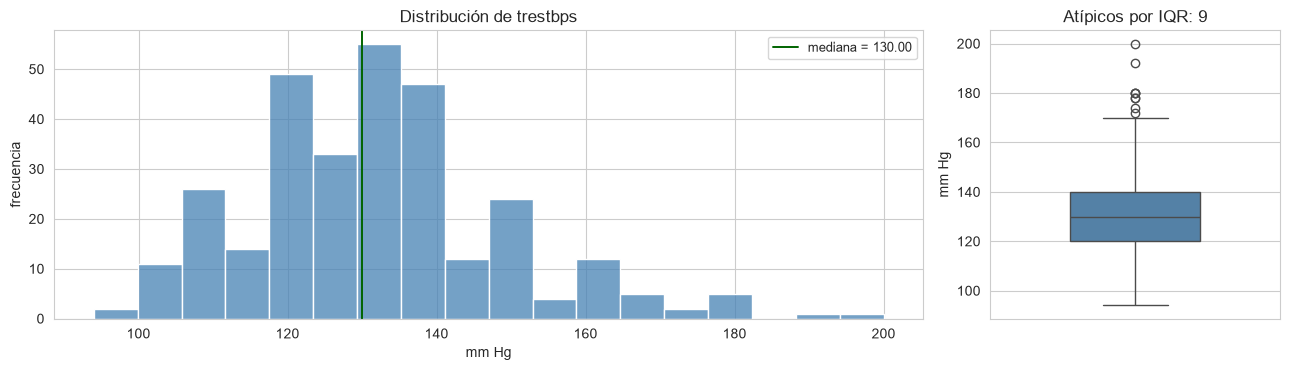

N,Mediana,W,p,Resultado
303,130.00,0.9665,1.80e-06,Se rechaza H₀


Límite inferior,Límite superior,Atípicos,Por debajo,Por encima
90.00,170.00,9 de 303 (2.97 %),0,9


In [ ]:
describir_continua("trestbps", "mm Hg")


**Normalidad.** Shapiro–Wilk obtuvo $W = 0{,}9665$ y $p = 1{,}80 \times 10^{-6}$. Como $p < 0{,}05$, se rechaza la hipótesis de normalidad para esta variable en la muestra completa.

**Valores atípicos.** Los límites de 1,5 IQR son 90,00 y 170,00 mm Hg. Se identifican 9 valores atípicos de 303 (2,97 %), todos por encima del límite superior. Los valores señalados van de 172,00 a 200,00 mm Hg.

### 4.3. chol - colesterol sérico


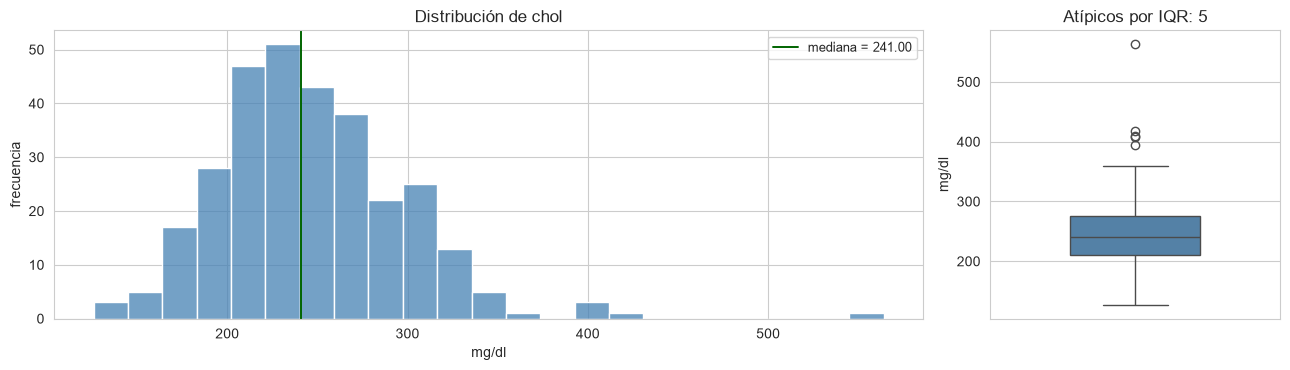

N,Mediana,W,p,Resultado
303,241.00,0.9473,5.91e-09,Se rechaza H₀


Límite inferior,Límite superior,Atípicos,Por debajo,Por encima
115.00,371.00,5 de 303 (1.65 %),0,5


In [ ]:
describir_continua("chol", "mg/dl")


**Normalidad.** Shapiro–Wilk obtuvo $W = 0{,}9473$ y $p = 5{,}91 \times 10^{-9}$. Como $p < 0{,}05$, se rechaza la hipótesis de normalidad para esta variable en la muestra completa.

**Valores atípicos.** Los límites de 1,5 IQR son 115,00 y 371,00 mg/dl. Se identifican 5 valores atípicos de 303 (1,65 %), todos por encima del límite superior. Los valores señalados van de 394,00 a 564,00 mg/dl.

### 4.4. thalach - frecuencia cardíaca máxima


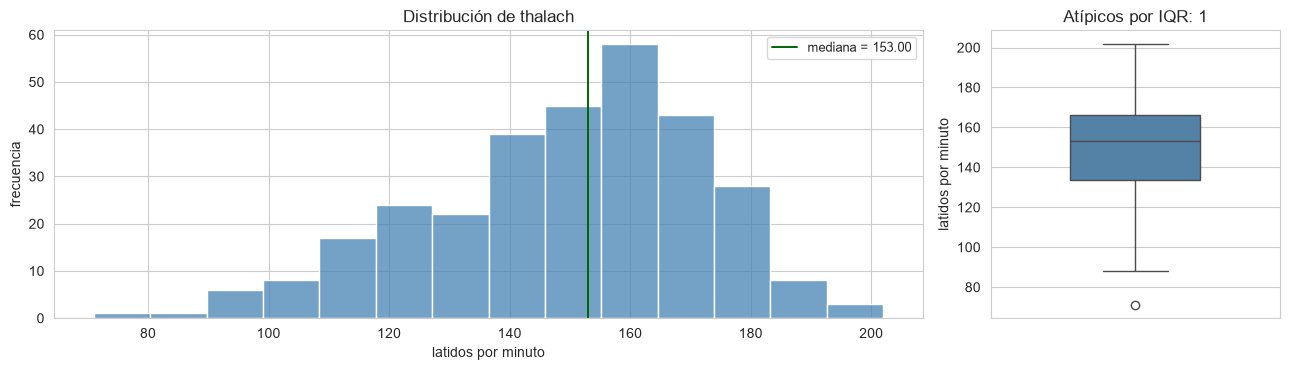

N,Mediana,W,p,Resultado
303,153.00,0.9765,7.00e-05,Se rechaza H₀


Límite inferior,Límite superior,Atípicos,Por debajo,Por encima
84.75,214.75,1 de 303 (0.33 %),1,0


In [ ]:
describir_continua("thalach", "latidos por minuto")


**Normalidad.** Shapiro–Wilk obtuvo $W = 0{,}9765$ y $p = 7{,}00 \times 10^{-5}$. Como $p < 0{,}05$, se rechaza la hipótesis de normalidad para esta variable en la muestra completa.

**Valores atípicos.** Los límites de 1,5 IQR son 84,75 y 214,75 latidos por minuto. Se identifica 1 valor atípico de 303 (0,33 %), por debajo del límite inferior. El valor señalado es 71,00 latidos por minuto.

### 4.5. oldpeak - depresión del segmento ST


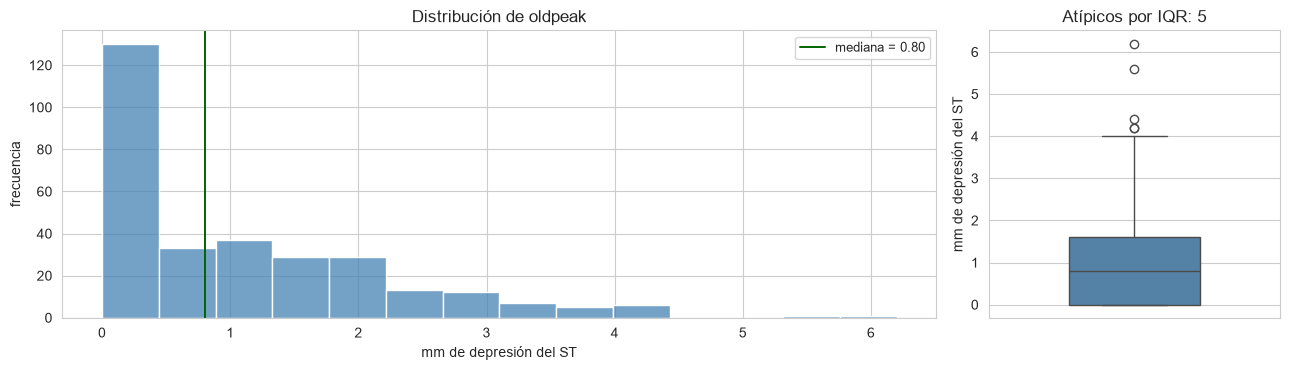

N,Mediana,W,p,Resultado
303,0.80,0.8442,8.18e-17,Se rechaza H₀


Límite inferior,Límite superior,Atípicos,Por debajo,Por encima
-2.40,4.00,5 de 303 (1.65 %),0,5


In [ ]:
describir_continua("oldpeak", "mm de depresión del ST")


**Normalidad.** Shapiro–Wilk obtuvo $W = 0{,}8442$ y $p = 8{,}18 \times 10^{-17}$. Como $p < 0{,}05$, se rechaza la hipótesis de normalidad para esta variable en la muestra completa.

**Valores atípicos.** Los límites de 1,5 IQR son -2,40 y 4,00 mm de depresión del ST. Se identifican 5 valores atípicos de 303 (1,65 %), todos por encima del límite superior. Los valores señalados van de 4,20 a 6,20 mm de depresión del ST.

### 4.6. sex - sexo


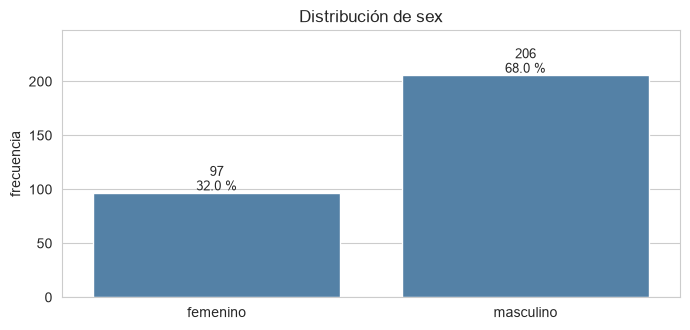

Valores observados: 303; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
         femenino          97        32.0
        masculino         206        68.0


In [ ]:
describir_frecuencias("sex", {0: "femenino", 1: "masculino"})


### 4.7. cp - tipo de dolor torácico


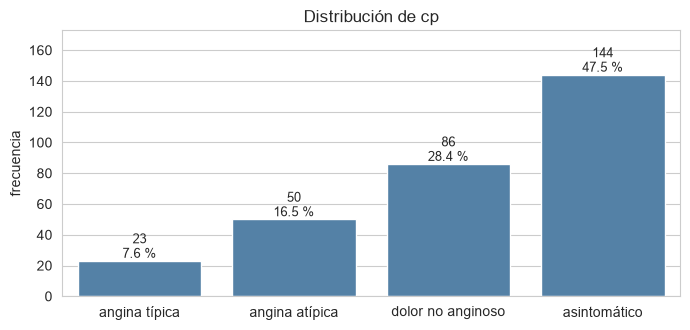

Valores observados: 303; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
    angina típica          23         7.6
   angina atípica          50        16.5
dolor no anginoso          86        28.4
     asintomático         144        47.5


In [ ]:
describir_frecuencias("cp", {1: "angina típica", 2: "angina atípica",
                            3: "dolor no anginoso", 4: "asintomático"})


### 4.8. fbs - glucosa en ayunas


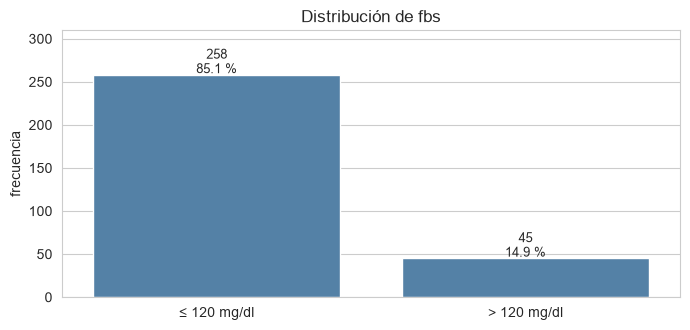

Valores observados: 303; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
      ≤ 120 mg/dl         258        85.1
      > 120 mg/dl          45        14.9


In [ ]:
describir_frecuencias("fbs", {0: "≤ 120 mg/dl", 1: "> 120 mg/dl"})


### 4.9. restecg - electrocardiograma en reposo


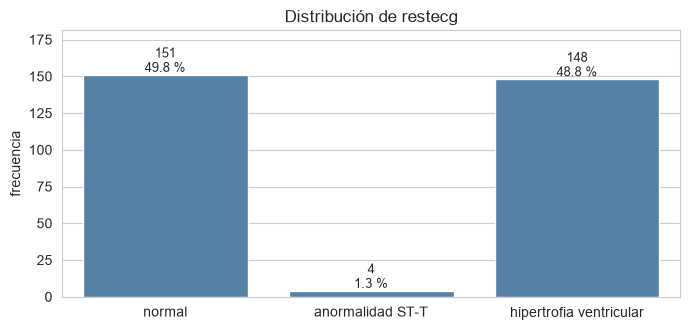

Valores observados: 303; porcentajes calculados sobre ese total.
      valor_o_categoria  frecuencia  porcentaje
                 normal         151        49.8
       anormalidad ST-T           4         1.3
hipertrofia ventricular         148        48.8


In [ ]:
describir_frecuencias("restecg", {0: "normal", 1: "anormalidad ST-T",
                                 2: "hipertrofia ventricular"})


### 4.10. exang - angina inducida por ejercicio


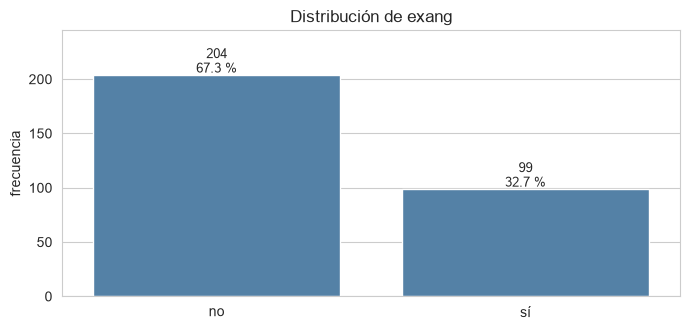

Valores observados: 303; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
               no         204        67.3
               sí          99        32.7


In [ ]:
describir_frecuencias("exang", {0: "no", 1: "sí"})


### 4.11. slope - pendiente del segmento ST


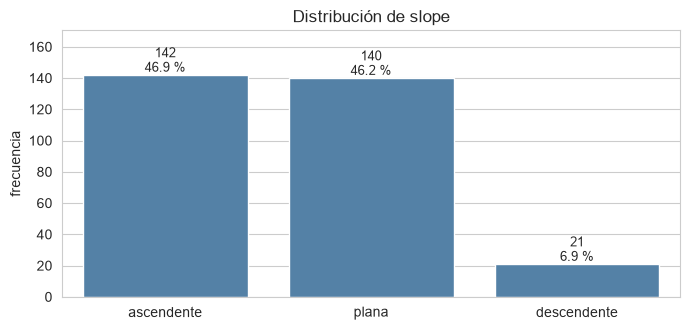

Valores observados: 303; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
       ascendente         142        46.9
            plana         140        46.2
      descendente          21         6.9


In [ ]:
describir_frecuencias("slope", {1: "ascendente", 2: "plana", 3: "descendente"})


### 4.12. ca - vasos principales


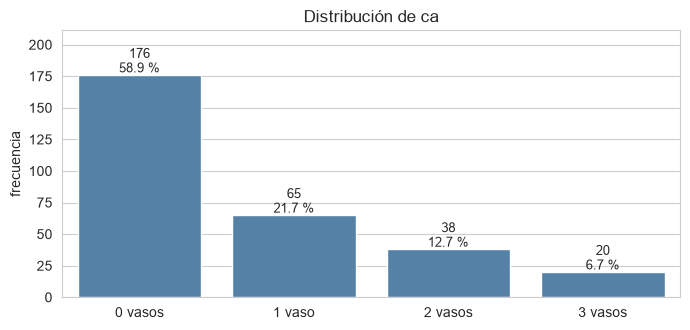

Valores observados: 299; porcentajes calculados sobre ese total.
valor_o_categoria  frecuencia  porcentaje
          0 vasos         176        58.9
           1 vaso          65        21.7
          2 vasos          38        12.7
          3 vasos          20         6.7


In [ ]:
describir_frecuencias("ca", {0: "0 vasos", 1: "1 vaso", 2: "2 vasos", 3: "3 vasos"})


### 4.13. thal - resultado de gammagrafía con talio


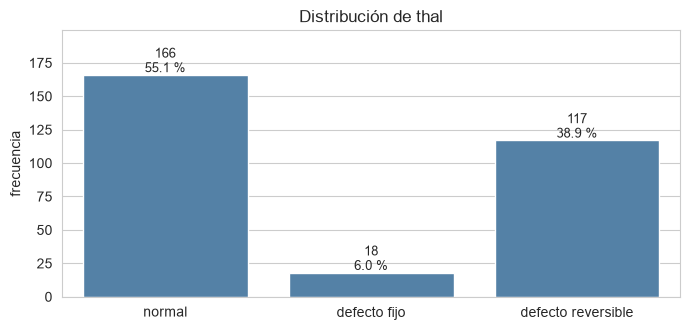

Valores observados: 301; porcentajes calculados sobre ese total.
 valor_o_categoria  frecuencia  porcentaje
            normal         166        55.1
      defecto fijo          18         6.0
defecto reversible         117        38.9


In [ ]:
describir_frecuencias("thal", {3: "normal", 6: "defecto fijo",
                              7: "defecto reversible"})


### 4.14. Síntesis del análisis univariante


In [ ]:
resumen_continuas = pd.DataFrame.from_dict(resultados_univariantes, orient="index")
resumen_continuas.index.name = "Variable"
resumen_univariante = pd.DataFrame({
    "N": resumen_continuas["n"],
    "p (Shapiro–Wilk)": resumen_continuas["p"].map(lambda v: f"{v:.2e}"),
    "Normalidad (α = 0.05)": resumen_continuas["p"].map(
        lambda p: "Se rechaza H₀" if p < ALFA_NORMALIDAD else "No se rechaza H₀"),
    "Atípicos IQR": resumen_continuas["atipicos"],
    "% por variable": (100 * resumen_continuas["atipicos"] / resumen_continuas["n"]).map(
        lambda v: f"{v:.2f} %"),
})
display(resumen_univariante.style.set_table_styles([
    {"selector": "caption", "props": [("text-align", "left"), ("font-weight", "bold"), ("padding", "8px 0")]},
    {"selector": "th", "props": [("background-color", "#eef3f7 !important"), ("color", "#182531 !important"), ("padding", "8px 12px")]},
    {"selector": "td", "props": [("padding", "8px 12px"), ("text-align", "center")]},
]).set_caption("Síntesis de las continuas · H₀: distribución normal"))
print(f"Variables con rechazo de normalidad: {int((resumen_continuas['p'] < ALFA_NORMALIDAD).sum())} de {len(resumen_continuas)}.")
print(f"Total de valores señalados por IQR: {int(resumen_continuas['atipicos'].sum())} (pueden corresponder a pacientes repetidos).")


,N,p (Shapiro–Wilk),Normalidad (α = 0.05),Atípicos IQR,% por variable
Variable,,,,,
age,303,6.07e-03,Se rechaza H₀,0,0.00 %
trestbps,303,1.80e-06,Se rechaza H₀,9,2.97 %
chol,303,5.91e-09,Se rechaza H₀,5,1.65 %
thalach,303,7.00e-05,Se rechaza H₀,1,0.33 %
oldpeak,303,8.18e-17,Se rechaza H₀,5,1.65 %


Variables con rechazo de normalidad: 5 de 5.
Total de valores señalados por IQR: 20 (pueden corresponder a pacientes repetidos).


**Normalidad.** Shapiro–Wilk rechaza la hipótesis de normalidad en las cinco continuas (`age`, `trestbps`, `chol`, `thalach` y `oldpeak`), con $p < 0{,}05$. Este resultado motivó optar por Mann–Whitney en el análisis bivariante, como decisión exploratoria coherente con el uso de pruebas por rangos para variables no normales en Peng et al. [5]. El rechazo global no establece la distribución dentro de cada grupo ni demuestra que Mann–Whitney sea la única opción válida; su fundamento metodológico se desarrolla en §6. Los contrastes de esa sección, tras Bonferroni, orientan la revisión de predictoras en §7, sin determinar por sí solos su exclusión.

**Valores atípicos.** IQR señala 9 valores en `trestbps`, 5 en `chol`, 1 en `thalach` y 5 en `oldpeak`; en `age` no señala ninguno. Son 20 mediciones por variable, que pueden corresponder a pacientes repetidos. Se conservan sin modificación para mantener las mediciones observadas de pacientes reales, conforme al criterio metodológico de este proyecto. El conjunto contiene solo 303 registros: eliminar pacientes por exceder los límites IQR reduciría una muestra ya limitada, sin que este criterio demuestre errores de registro. Su detección caracteriza la distribución y la frecuencia de valores extremos; no se utiliza como filtro de eliminación. El corpus reconoce la presencia de atípicos en datos clínicos [3], aunque [6] y [7] modifican sus extremos; la conservación de los valores originales es una decisión propia del presente EDA.


In [ ]:
resumen_frecuencias = []
for columna in variables_por_frecuencias:
    conteo = df[columna].value_counts().sort_index()
    resumen_frecuencias.append({
        "variable": columna,
        "N observado": int(conteo.sum()),
        "Valores distintos": len(conteo),
        "Valor modal": int(conteo.idxmax()),
        "% modal": round(conteo.max() / conteo.sum() * 100, 1),
        "Frecuencia mínima": int(conteo.min()),
        "% menor": round(conteo.min() / conteo.sum() * 100, 1),
    })

resumen_frecuencias = pd.DataFrame(resumen_frecuencias).set_index("variable")
print(resumen_frecuencias.to_string())


          N observado  Valores distintos  Valor modal  % modal  Frecuencia mínima  % menor
variable                                                                                  
sex               303                  2            1     68.0                 97     32.0
cp                303                  4            4     47.5                 23      7.6
fbs               303                  2            0     85.1                 45     14.9
restecg           303                  3            0     49.8                  4      1.3
exang             303                  2            0     67.3                 99     32.7
slope             303                  3            1     46.9                 21      6.9
ca                299                  4            0     58.9                 20      6.7
thal              301                  3            3     55.1                 18      6.0


**Frecuencias.** Las distribuciones muestran valores o categorías con pocos registros: `restecg = 1` reúne 4 de 303 (1,3 %), `thal = 6`, 18 de 301 (6,0 %), `ca = 3`, 20 de 299 (6,7 %), `slope = 3`, 21 de 303 (6,9 %), y `cp = 1`, 23 de 303 (7,6 %). Estos recuentos describen su representación en la muestra; no demuestran sesgo ni justifican eliminar predictoras. La escasa representación de `restecg = 1` se considera al interpretar su contraste en §6.

## 5. Binarización de la variable objetivo


### 5.1. Naturaleza de la variable y objetivo del análisis

El conjunto Cleveland registra el diagnóstico angiográfico en `num`. La documentación completa de atributos de UCI lo describe mediante dos estados —ausencia y presencia de enfermedad—, pero el resumen del repositorio y los datos del archivo contienen cinco códigos: 0, 1, 2, 3 y 4 [1]. Por tanto, el desenlace se describe en términos binarios, aunque la variable original no está codificada únicamente con dos valores.

El proyecto se orienta a detectar si el paciente presenta o no enfermedad, no a diferenciar los códigos diagnósticos 1–4. Para responder esa pregunta y definir los grupos del análisis bivariante, se requiere expresar el diagnóstico como ausencia o presencia.


### 5.2. Fundamento de la decisión

UCI señala explícitamente que los experimentos con Cleveland han distinguido presencia de enfermedad, correspondiente a los valores 1–4, frente a ausencia, correspondiente al valor 0 [1]. Se adopta esa agrupación porque coincide con la pregunta del proyecto y concilia los códigos observados con los dos estados descritos por la fuente. La tabla siguiente presenta las frecuencias originales antes de aplicar la binarización.


In [ ]:
distribucion_num = df["num"].value_counts().sort_index()
niveles = pd.DataFrame({
    "registros": distribucion_num,
    "porcentaje": distribucion_num / len(df) * 100,
})
niveles.index.name = "num"
display(niveles.style.format({"porcentaje": "{:.2f} %"}))


### 5.3. Criterio de binarización y aplicación

Se asigna 0 a `num = 0` y 1 a `num > 0`, agrupando los códigos 1–4 como presencia de enfermedad [1]. Antes de aplicar el criterio se comprueba que no existan ausentes ni valores fuera del dominio documentado 0–4. Se conserva `num` y se incorpora la columna `objetivo`, de modo que la agrupación sea trazable y los códigos originales permanezcan disponibles.


In [ ]:
if df["num"].isna().any() or not df["num"].isin([0, 1, 2, 3, 4]).all():
    raise ValueError("num contiene ausentes o códigos fuera del dominio documentado 0–4.")
df["objetivo"] = (df["num"] > 0).astype(int)

binaria = df["objetivo"].value_counts().reindex([0, 1], fill_value=0)
resumen_objetivo = pd.DataFrame({
    "Clase": ["Ausencia (0)", "Presencia (1)"],
    "Registros": binaria.values,
    "Porcentaje": binaria.values / len(df) * 100,
})
display(resumen_objetivo.style.hide(axis="index").format({"Porcentaje": "{:.2f} %"}))
if binaria.min() > 0:
    print(f"Razón entre clases: {binaria.max() / binaria.min():.2f} a 1")


In [ ]:
conteo = df["objetivo"].value_counts().sort_index()

plt.figure(figsize=(6, 3.6))
ejes = sns.barplot(x=["ausencia (0)", "presencia (1)"], y=conteo.values,
                   color="steelblue")
for i, v in enumerate(conteo.values):
    ejes.text(i, v + 3, f"{v}\n{v / conteo.sum() * 100:.1f} %",
              ha="center", fontsize=10)
ejes.set_title("Distribución de la variable objetivo binarizada")
ejes.set_ylabel("frecuencia")
ejes.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()


### 5.4. Decisión de balanceo y elección de SMOTE-NC

La binarización produce 164 registros sin enfermedad (54,13 %) y 139 con enfermedad (45,87 %), una razón de 1,18 a 1. El desbalance es leve; esa cifra no demuestra por sí sola que un modelo vaya a perder sensibilidad. La decisión de balancear se adopta antes del entrenamiento como medida de preprocesamiento para que los casos con enfermedad, menos representados en un conjunto de solo 303 registros, no pierdan peso relativo durante el ajuste. El EDA no atribuye a esta medida una mejora de rendimiento todavía no observada.

El antecedente más cercano es Khande et al. [9]: trabajan con Cleveland, describen un desbalance también leve y aplican SMOTE al conjunto de entrenamiento ante el posible sesgo hacia la clase mayoritaria. Informan aproximadamente 165 casos negativos y 140 positivos, aunque esas cifras suman 305 y el propio artículo declara 303 registros; por ello no se usan como una coincidencia numérica exacta con nuestra muestra. El trabajo informa cualitativamente una mejora del *recall* tras SMOTE, pero no ofrece una tabla cuantificada del mismo modelo con y sin remuestreo. Por ello se utiliza como precedente de la decisión, sin trasladar una magnitud de mejora a este proyecto.

Antes del balanceo se realizará una partición 80/20 estratificada por el diagnóstico binario, para mantener aproximadamente la proporción de ambas clases en entrenamiento y prueba. Chakraborty et al. [7] emplean esa partición estratificada; Çakmak et al. [6] preservan las proporciones del diagnóstico mediante validación cruzada estratificada. La estratificación por diagnóstico no garantiza la representación de todas las categorías de las predictoras ni demuestra ausencia de sesgo. Sus frecuencias se describen en §4.

La técnica se aplicará únicamente al entrenamiento, después de la partición, y se limitará a igualar las clases. Las muestras sintéticas no representan pacientes clínicos nuevos. El conjunto de prueba conservará su distribución original; si se utiliza validación cruzada, el remuestreo se ajustará dentro de cada pliegue de entrenamiento.

Una vez decidido el balanceo, la composición de las variables determina la variante. Cleveland combina atributos continuos con variables nominales codificadas mediante enteros. En `thal`, por ejemplo, 3, 6 y 7 son categorías y no magnitudes; interpolar esos códigos mediante SMOTE estándar puede generar valores ajenos al dominio de la variable. SMOTE-NC está diseñado para conjuntos con atributos numéricos y categóricos, de modo que se elige para preservar los valores admitidos de las variables nominales al generar muestras sintéticas. La variable `ca` sigue siendo un conteo discreto, no nominal. Para evitar que la interpolación genere vasos fraccionarios, se incluye entre los atributos que SMOTE-NC trata como categorías durante el remuestreo. Esta es una restricción computacional sobre la generación sintética: preserva el dominio observado 0–3, pero no aprovecha el orden del conteo al calcular vecindades. En la preparación de los modelos `ca` conserva su carácter numérico.

Iscra et al. [10] describen SMOTE-NC para datos clínicos mixtos y lo evalúan frente a NearMiss, SMOTE-Tomek y SMOTE-ENN, además de modelos entrenados sin remuestreo. Reportan resultados favorables para SMOTE-NC en su conjunto de pacientes con ictus. El artículo no incluye SMOTE estándar como método independiente y estudia una población con un desbalance mayor que el de Cleveland. Respalda la pertinencia y viabilidad empírica de la variante; la preferencia frente a SMOTE estándar en este proyecto se fundamenta principalmente en la validez de los valores categóricos sintéticos.


## 6. Análisis bivariante

Se comparan las trece predictoras entre ausencia y presencia de enfermedad para identificar asociaciones individuales y describir las diferencias observadas. Los resultados orientan la revisión de las variables; no prueban su utilidad predictiva conjunta ni determinan su exclusión.

**Descripción y contrastes.** Se presentan medianas y cuartiles [Q1, Q3] para las continuas, y recuentos y porcentajes por valor para las demás variables, siguiendo a Peng et al. [5] y Xiang et al. [11]. Xiang et al. comparan las continuas mediante Wilcoxon de suma de rangos y las categóricas mediante Chi-cuadrado [11]. Aquí se utiliza Mann–Whitney U bilateral para las cinco continuas; su equivalencia con la suma de rangos y la implementación están documentadas en [12]. Se adopta el cálculo asintótico con ajuste por empates, presentes en las cinco variables, y se desactiva explícitamente la corrección opcional de continuidad [12]. El rechazo de normalidad global en §4 motivó esta elección como antecedente exploratorio, junto al uso de pruebas por rangos descrito por Peng et al. [5] y Xiang et al. [11]. No se interpreta como una comprobación de normalidad dentro de cada grupo ni como una obligación automática de usar Mann–Whitney; el contraste tampoco se reduce exclusivamente a diferencias de medianas.

Las ocho tablas restantes se contrastan con Chi-cuadrado de independencia de Pearson, con antecedentes en [5], [11], y sin corrección de continuidad [13]. Para `ca`, los valores documentados 0–3 [1] se usan como filas de la tabla de frecuencias, sin cambiar su naturaleza cuantitativa discreta: se compara la distribución de pacientes por número de vasos y diagnóstico, no una tendencia por incremento. Esta representación es una adaptación propia al formato de tabla de contingencia de [13], no un uso específico de `ca` atribuido a los artículos.

**Adecuación y comparaciones múltiples.** Se revisan los recuentos esperados; los inferiores a cinco se señalan como precaución de la aproximación, conforme a la guía de [13], sin tratarlos como una frontera absoluta de validez. Los casos señalados se describen como resultados aproximados con limitación, sin añadir contrastes para resolverla. Se aplica Bonferroni sobre los 13 valores p, con antecedente en Çakmak et al. [6]: p ajustado = mínimo(13p, 1), con α = 0,05. El ajuste no subsana las limitaciones del contraste original.

Se conservan los atípicos y se omiten los ausentes por variable. Las once predictoras completas usan 303 registros; `ca`, 299, y `thal`, 301. Estos análisis preceden a la eliminación de los seis registros incompletos y no utilizan todavía el conjunto de 297 casos del preprocesamiento.


In [27]:
ALFA_BIVARIANTE = 0.05
CONTINUAS_BIVARIANTE = ["age", "trestbps", "chol", "thalach", "oldpeak"]
UNIDADES_BIVARIANTE = {"age": "años", "trestbps": "mm Hg", "chol": "mg/dl",
                       "thalach": "latidos por minuto", "oldpeak": "mm de depresión del ST"}
ETIQUETAS_BIVARIANTE = {
    "sex": {0: "femenino", 1: "masculino"},
    "cp": {1: "angina típica", 2: "angina atípica", 3: "dolor no anginoso", 4: "asintomático"},
    "fbs": {0: "≤ 120 mg/dl", 1: "> 120 mg/dl"},
    "restecg": {0: "normal", 1: "anormalidad ST-T", 2: "hipertrofia ventricular"},
    "exang": {0: "no", 1: "sí"},
    "slope": {1: "ascendente", 2: "plana", 3: "descendente"},
    "ca": {0: "0 vasos", 1: "1 vaso", 2: "2 vasos", 3: "3 vasos"},
    "thal": {3: "normal", 6: "defecto fijo", 7: "defecto reversible"},
}
PREDICTORAS_BIVARIANTE = CONTINUAS_BIVARIANTE + list(ETIQUETAS_BIVARIANTE)
assert df["objetivo"].notna().all() and set(df["objetivo"].unique()) == {0, 1}
resultados_bivariantes = {}


def mostrar_tabla_bivariante(tabla, titulo, formatos=None, ocultar_indice=True):
    estilo = tabla.style
    if ocultar_indice:
        estilo = estilo.hide(axis="index")
    if formatos:
        estilo = estilo.format(formatos)
    display(estilo.set_caption(titulo).set_table_styles([
        {"selector": "caption", "props": [("text-align", "left"), ("font-weight", "bold"), ("padding", "8px 0")]},
        {"selector": "th", "props": [("background-color", "#eef3f7 !important"),
                                     ("color", "#182531 !important"), ("padding", "8px 12px")]},
        {"selector": "td", "props": [("padding", "8px 12px"), ("text-align", "center")]},
    ]))


### 6.1. Variables continuas por diagnóstico


In [28]:
descripcion_continuas = []
for columna in CONTINUAS_BIVARIANTE:
    observados = df[columna].notna()
    valores = df.loc[observados, columna]
    diagnostico = df.loc[observados, "objetivo"]
    ausencia, presencia = valores[diagnostico == 0], valores[diagnostico == 1]


    U, p = stats.mannwhitneyu(ausencia, presencia, alternative="two-sided",
                            method="asymptotic", use_continuity=False)
    resultados_bivariantes[columna] = {
        "n": len(valores), "prueba": "Mann–Whitney U", "estadistico": float(U),
        "p": float(p), "esperado_minimo": np.nan, "celdas_esperadas_menores_5": 0,
        "aproximacion_limitada": False,
    }
    for nombre, grupo in [("Ausencia", ausencia), ("Presencia", presencia)]:
        descripcion_continuas.append({
            "Variable": columna, "Unidad": UNIDADES_BIVARIANTE[columna],
            "Diagnóstico": nombre, "N": len(grupo), "Mediana": grupo.median(),
            "Q1": grupo.quantile(.25), "Q3": grupo.quantile(.75),
        })

mostrar_tabla_bivariante(pd.DataFrame(descripcion_continuas),
                        "Continuas por diagnóstico · mediana y cuartiles",
                        {"Mediana": "{:.2f}", "Q1": "{:.2f}", "Q3": "{:.2f}"})


Variable,Unidad,Diagnóstico,N,Mediana,Q1,Q3
age,años,Ausencia,164,52.00,44.75,59.00
age,años,Presencia,139,58.00,52.00,62.00
trestbps,mm Hg,Ausencia,164,130.00,120.00,140.00
trestbps,mm Hg,Presencia,139,130.00,120.00,145.00
chol,mg/dl,Ausencia,164,234.50,208.75,267.25
chol,mg/dl,Presencia,139,249.00,217.50,283.50
thalach,latidos por minuto,Ausencia,164,161.00,148.75,172.00
thalach,latidos por minuto,Presencia,139,142.00,125.00,156.50
oldpeak,mm de depresión del ST,Ausencia,164,0.20,0.00,1.02
oldpeak,mm de depresión del ST,Presencia,139,1.40,0.55,2.50


### 6.2. Distribución por valores y diagnóstico


In [29]:
descripcion_frecuencias = []
for columna, etiquetas in ETIQUETAS_BIVARIANTE.items():
    observados = df[columna].notna()
    tabla = pd.crosstab(df.loc[observados, columna], df.loc[observados, "objetivo"])
    tabla = tabla.reindex(columns=[0, 1], fill_value=0)


    chi2, p, gl, esperados = stats.chi2_contingency(tabla, correction=False)
    pequenas = int((esperados < 5).sum())
    resultados_bivariantes[columna] = {
        "n": int(tabla.to_numpy().sum()), "prueba": "Chi-cuadrado de Pearson",
        "estadistico": float(chi2), "p": float(p),
        "esperado_minimo": float(esperados.min()), "celdas_esperadas_menores_5": pequenas,
        "aproximacion_limitada": pequenas > 0,
    }
    for valor, fila in tabla.iterrows():
        total = int(fila.sum())
        descripcion_frecuencias.append({
            "Variable": columna, "Valor": int(valor), "Descripción": etiquetas[int(valor)],
            "N": total, "Ausencia": int(fila[0]), "Presencia": int(fila[1]),
            "% con enfermedad": 100 * fila[1] / total,
        })

mostrar_tabla_bivariante(pd.DataFrame(descripcion_frecuencias),
                        "Recuentos por valor y diagnóstico · porcentajes dentro de cada valor",
                        {"% con enfermedad": "{:.2f} %"})


Variable,Valor,Descripción,N,Ausencia,Presencia,% con enfermedad
sex,0,femenino,97,72,25,25.77 %
sex,1,masculino,206,92,114,55.34 %
cp,1,angina típica,23,16,7,30.43 %
cp,2,angina atípica,50,41,9,18.00 %
cp,3,dolor no anginoso,86,68,18,20.93 %
cp,4,asintomático,144,39,105,72.92 %
fbs,0,≤ 120 mg/dl,258,141,117,45.35 %
fbs,1,> 120 mg/dl,45,23,22,48.89 %
restecg,0,normal,151,95,56,37.09 %
restecg,1,anormalidad ST-T,4,1,3,75.00 %


### 6.3. Síntesis del análisis bivariante


In [30]:
assert set(resultados_bivariantes) == set(PREDICTORAS_BIVARIANTE)
sintesis_bivariante = pd.DataFrame([resultados_bivariantes[c] for c in PREDICTORAS_BIVARIANTE],
                                 index=PREDICTORAS_BIVARIANTE)
sintesis_bivariante.index.name = "Variable"
sintesis_bivariante["p_bonferroni"] = (len(PREDICTORAS_BIVARIANTE) * sintesis_bivariante["p"]).clip(upper=1)
sintesis_bivariante["resultado"] = np.where(
    sintesis_bivariante["p_bonferroni"] < ALFA_BIVARIANTE,
    "Asociación significativa", "Sin significancia tras ajuste")
sintesis_bivariante.loc[sintesis_bivariante["aproximacion_limitada"], "resultado"] = "Resultado aproximado con limitación"
mostrar_tabla_bivariante(sintesis_bivariante[["n", "prueba", "p", "p_bonferroni", "resultado"]].rename(columns={
    "n": "N", "prueba": "Prueba", "p": "p original", "p_bonferroni": "p Bonferroni", "resultado": "Interpretación"}),
    "Asociación individual · 13 contrastes · α = 0,05",
    {"p original": "{:.2e}", "p Bonferroni": "{:.2e}"}, ocultar_indice=False)


,N,Prueba,p original,p Bonferroni,Interpretación
Variable,,,,,
age,303,Mann–Whitney U,3.91e-05,5.08e-04,Asociación significativa
trestbps,303,Mann–Whitney U,2.59e-02,3.37e-01,Sin significancia tras ajuste
chol,303,Mann–Whitney U,3.53e-02,4.59e-01,Sin significancia tras ajuste
thalach,303,Mann–Whitney U,1.85e-13,2.41e-12,Asociación significativa
oldpeak,303,Mann–Whitney U,6.78e-13,8.81e-12,Asociación significativa
sex,303,Chi-cuadrado de Pearson,1.45e-06,1.88e-05,Asociación significativa
cp,303,Chi-cuadrado de Pearson,1.25e-17,1.63e-16,Asociación significativa
fbs,303,Chi-cuadrado de Pearson,6.60e-01,1.00e+00,Sin significancia tras ajuste
restecg,303,Chi-cuadrado de Pearson,6.57e-03,8.54e-02,Resultado aproximado con limitación


**Asociación individual.** Tras Bonferroni, nueve predictoras presentan asociación significativa con el diagnóstico: `age`, `thalach`, `oldpeak`, `sex`, `cp`, `exang`, `slope`, `ca` y `thal`. `trestbps`, `chol` y `fbs` no alcanzan el umbral ajustado; ello no demuestra que carezcan de utilidad conjunta ni determina su eliminación. Las medianas describen mayor edad y mayor `oldpeak`, y menor `thalach`, en el grupo con enfermedad; los contrastes por rangos no se reducen a esas diferencias de medianas.

**Limitación de `restecg`.** La categoría de anormalidad ST-T contiene cuatro registros: uno sin enfermedad y tres con enfermedad. Sus recuentos esperados son 2,17 y 1,83, inferiores a la guía de cinco [13]. Pearson produce p = 0,00657 y Bonferroni p = 0,08536; el ajuste no elimina la limitación de la aproximación. Se conserva el resultado como aproximado con limitación, sin concluir ausencia de asociación ni incorporar un contraste adicional.

**Continuidad del análisis.** `trestbps`, `chol` y `fbs` quedan señaladas por no alcanzar significancia ajustada, y `restecg` por la limitación indicada. La sección 7 examina relaciones entre predictoras y posible redundancia para contextualizar estos resultados. Se mantienen las trece predictoras como punto de partida, sin usar significancia o redundancia como filtros automáticos; §6 no modifica por sí sola las decisiones de preprocesamiento.


## 7. Relaciones lineales entre predictoras y multicolinealidad

El análisis individual de §6 no determina si existen relaciones entre predictoras que motiven revisar su conservación. Se examinan las relaciones lineales por parejas mediante Pearson y las dependencias que involucran varias columnas mediante el factor de inflación de la varianza (VIF). Ambos análisis sirven como diagnóstico exploratorio de redundancia; no demuestran utilidad predictiva conjunta ni establecen exclusiones automáticas.

Chakraborty et al. calculan Pearson entre variables numéricas y revisan parejas con |r| > 0,85 [7]. Peng et al. evalúan multicolinealidad mediante VIF y emplean un umbral de cinco [5]; Sovia et al. también utilizan VIF, con umbral diez [3]. Aquí se adopta **VIF > 5 como señal de revisión**, coherente con la recomendación de investigar valores superiores a cinco descrita por Gaskin et al. [14, §2.4.2]. Los umbrales se aplican a sus medidas respectivas.

Las trece predictoras se incorporan al diagnóstico VIF. Las binarias conservan sus indicadores 0/1; `cp`, `restecg`, `slope` y `thal` se representan mediante indicadores con categoría de referencia. Chakraborty respalda la codificación mediante indicadores [7]; Gaskin describe explícitamente la reserva de una referencia y la incorporación separada de los indicadores nominales [14, tabla 1 y §2.5.4]. Representar los niveles de `slope` mediante indicadores es una adaptación propia que evita imponer distancias iguales entre sus códigos. `ca` conserva sus valores de conteo y su naturaleza discreta [1], [2].

Como convención de implementación, la referencia es el menor código observado de cada variable. Se incluyen los restantes indicadores y un intercepto en las regresiones auxiliares. La identidad entre la suma de todos los indicadores y una columna de unos explica técnicamente esta representación reducida; no se atribuye esa demostración algebraica al artículo de Gaskin. El VIF se informa por columna representada, no como un índice agregado de toda una variable categórica.

Ambos cálculos utilizan la misma copia de registros completos en las trece predictoras. Esta selección permite compararlos sobre una muestra común; no modifica `df` ni anticipa la decisión de tratamiento de ausentes. La representación se destina a este diagnóstico del EDA y no fija la codificación del entrenamiento. Su alcance es lineal: valores bajos no prueban independencia completa ni descartan otras formas de relación.


### 7.1. Correlación entre predictoras cuantitativas

Se calcula Pearson para las cinco continuas y el conteo `ca`, conservando el signo de cada coeficiente. La matriz describe relaciones lineales; no se realizan contrastes de significancia ni se deriva la elección del coeficiente de Shapiro global. Se revisan únicamente parejas con |r| > 0,85, siguiendo el antecedente de [7].


Muestra común: 297 de 303 registros; 6 excluidos únicamente de estos cálculos por ausentes.


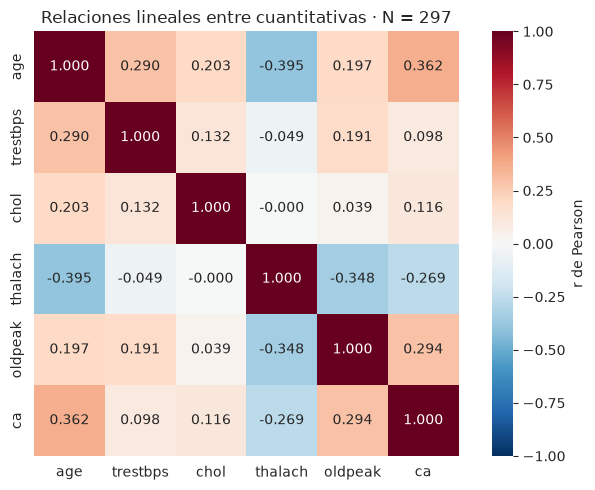

Parejas con |r| > 0.85: 0 de 15.


In [32]:
CUANTITATIVAS_7 = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
BINARIAS_7 = ["sex", "fbs", "exang"]
MULTICATEGORICAS_7 = ["cp", "restecg", "slope", "thal"]
PREDICTORAS_7 = CUANTITATIVAS_7 + BINARIAS_7 + MULTICATEGORICAS_7
UMBRAL_PEARSON_7 = 0.85
UMBRAL_VIF_7 = 5.0

muestra_7 = df.loc[:, PREDICTORAS_7].dropna().copy()
if muestra_7.empty or not np.isfinite(muestra_7.to_numpy(dtype=float)).all():
    raise ValueError("El diagnóstico requiere registros completos y finitos")
if (muestra_7.nunique() < 2).any():
    raise ValueError("El diagnóstico requiere variación en todas las predictoras")

print(f"Muestra común: {len(muestra_7)} de {len(df)} registros; "
      f"{len(df) - len(muestra_7)} excluidos únicamente de estos cálculos por ausentes.")

correlacion_7 = muestra_7[CUANTITATIVAS_7].corr(method="pearson")
pares_pearson_7 = pd.DataFrame([
    {"Variable A": a, "Variable B": b, "r": correlacion_7.loc[a, b]}
    for i, a in enumerate(CUANTITATIVAS_7)
    for b in CUANTITATIVAS_7[i + 1:]
])
pares_revision_7 = pares_pearson_7.loc[
    pares_pearson_7["r"].abs() > UMBRAL_PEARSON_7
].copy()

fig_7, ax_7 = plt.subplots(figsize=(7, 5))
sns.heatmap(correlacion_7, annot=True, fmt=".3f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"label": "r de Pearson"}, ax=ax_7)
ax_7.set_title(f"Relaciones lineales entre cuantitativas · N = {len(muestra_7)}")
fig_7.tight_layout()
plt.show()

print(f"Parejas con |r| > {UMBRAL_PEARSON_7:.2f}: "
      f"{len(pares_revision_7)} de {len(pares_pearson_7)}.")
if not pares_revision_7.empty:
    mostrar_tabla_bivariante(pares_revision_7, "Parejas que requieren revisión",
                            {"r": "{:.3f}"})


### 7.2. Factor de inflación de la varianza

Pearson describe cada pareja por separado. VIF examina cuánto puede explicarse linealmente una columna mediante las restantes: VIF = 1 / (1 − R²), donde R² procede de una regresión auxiliar con intercepto. Las columnas indicadoras permiten incorporar las categóricas sin tratar sus códigos como magnitudes [14].

Se muestran las referencias adoptadas y el VIF de cada columna. El umbral cinco orienta una revisión; no demuestra que la variable completa sea prescindible. Los VIF de los indicadores dependen de la representación y la categoría de referencia, por lo que no se comparan como un ranking de importancia predictiva.


In [33]:
referencias_7 = pd.DataFrame([
    {"Variable": c, "Código de referencia": int(muestra_7[c].min()),
     "Categoría de referencia": ETIQUETAS_BIVARIANTE[c][int(muestra_7[c].min())]}
    for c in MULTICATEGORICAS_7
])

categorias_7 = muestra_7[MULTICATEGORICAS_7].astype("category")
indicadores_7 = pd.get_dummies(categorias_7, drop_first=True, dtype=float)
diseno_7 = pd.concat([
    muestra_7[CUANTITATIVAS_7 + BINARIAS_7].astype(float), indicadores_7
], axis=1)

filas_vif_7 = []
for columna_7 in diseno_7.columns:
    respuesta_7 = diseno_7[columna_7]
    restantes_7 = diseno_7.drop(columns=columna_7)
    auxiliar_7 = LinearRegression(fit_intercept=True).fit(restantes_7, respuesta_7)
    r2_7 = float(auxiliar_7.score(restantes_7, respuesta_7))
    valor_vif_7 = np.inf if r2_7 >= 1.0 else 1.0 / (1.0 - r2_7)
    variable_7 = columna_7.split("_", 1)[0]
    filas_vif_7.append({
        "Variable": variable_7, "Columna evaluada": columna_7,
        "VIF": valor_vif_7,
        "Revisar (VIF > 5)": "Sí" if valor_vif_7 > UMBRAL_VIF_7 else "No",
    })

tabla_vif_7 = pd.DataFrame(filas_vif_7)
mostrar_tabla_bivariante(referencias_7, "Categorías de referencia del diagnóstico")
mostrar_tabla_bivariante(tabla_vif_7,
                        f"Multicolinealidad · {len(PREDICTORAS_7)} predictoras · "
                        f"{diseno_7.shape[1]} columnas · N = {len(muestra_7)}",
                        {"VIF": "{:.3f}"})
print(f"Columnas con VIF > {UMBRAL_VIF_7:g}: "
      f"{int((tabla_vif_7['VIF'] > UMBRAL_VIF_7).sum())} "
      f"de {len(tabla_vif_7)}.")


Variable,Código de referencia,Categoría de referencia
cp,1,angina típica
restecg,0,normal
slope,1,ascendente
thal,3,normal


Variable,Columna evaluada,VIF,Revisar (VIF > 5)
age,age,1.503,No
trestbps,trestbps,1.227,No
chol,chol,1.151,No
thalach,thalach,1.736,No
oldpeak,oldpeak,1.867,No
ca,ca,1.377,No
sex,sex,1.342,No
fbs,fbs,1.127,No
exang,exang,1.435,No
cp,cp_2,2.880,No


Columnas con VIF > 5: 0 de 18.


### 7.3. Síntesis y conservación de predictoras

Sobre los **297 registros completos**, ninguna de las quince parejas cuantitativas supera |r| > 0,85 [7]. La mayor correlación absoluta corresponde a `age` y `thalach` (**r = −0,395**). El diagnóstico VIF incorpora las trece predictoras mediante dieciocho columnas; ninguna supera cinco [5], [14]. El máximo es **4,340**, correspondiente al indicador `cp = 4` con `cp = 1` como referencia. Este valor pertenece a ese indicador y no constituye un VIF agregado de `cp` ni una medida de utilidad predictiva.

Con esta representación y estos criterios, **no se encuentran señales de redundancia lineal o multicolinealidad que justifiquen retirar alguna predictora**. Se mantiene la conservación de las trece, incluidas `oldpeak`, `slope` y `fbs`. La ausencia de significancia ajustada de `trestbps`, `chol` y `fbs` en §6 y la limitación de `restecg` no se convierten en exclusiones automáticas. Estos resultados tampoco acreditan independencia completa, ausencia de relaciones no lineales ni aporte predictivo adicional de cada variable.

La conservación no resuelve la escasa representación de algunas categorías, descrita en §4; la limitación de `restecg` permanece explícita en §6. La partición estratificada por diagnóstico se fundamenta en §5.4. El siguiente apartado aborda la decisión sobre los valores ausentes.


## 8. Decisión sobre los valores ausentes

La sección 3 identificó seis registros incompletos: cuatro con ausencia en `ca` y dos en `thal`. Tras mantener ambas predictoras en las secciones 6 y 7, se examina el coste de excluir esos registros para preparar los datos del entrenamiento.

### 8.1. Impacto de la eliminación

In [ ]:
completos_8 = df.dropna().copy()
impacto_ausentes_8 = pd.DataFrame({
    "Característica": ["Registros", "Sin enfermedad", "Con enfermedad",
                       "Proporción con enfermedad"],
    "Conjunto original": [
        str(len(df)),
        str(int((df["objetivo"] == 0).sum())),
        str(int((df["objetivo"] == 1).sum())),
        f"{df['objetivo'].mean() * 100:.2f} %",
    ],
    "Registros completos": [
        str(len(completos_8)),
        str(int((completos_8["objetivo"] == 0).sum())),
        str(int((completos_8["objetivo"] == 1).sum())),
        f"{completos_8['objetivo'].mean() * 100:.2f} %",
    ],
})
registros_excluidos_8 = len(df) - len(completos_8)
porcentaje_excluido_8 = registros_excluidos_8 / len(df) * 100
cambio_proporcion_8 = (completos_8["objetivo"].mean() - df["objetivo"].mean()) * 100
mostrar_tabla_bivariante(impacto_ausentes_8, "Impacto de excluir los registros incompletos")


Característica,Conjunto original,Registros completos
Registros,303,297
Sin enfermedad,164,160
Con enfermedad,139,137
Proporción con enfermedad,45.87 %,46.13 %


La eliminación supone perder el **1,98 % de los registros** y aumentar la proporción con enfermedad en **0,25 puntos porcentuales**.

### 8.2. Decisión adoptada

Se decide **eliminar los seis registros incompletos durante el preprocesamiento**, conservando las trece predictoras. Como criterio propio del proyecto, se prioriza trabajar con mediciones observadas y reducir la incorporación de valores estimados u observaciones sintéticas. Se acepta, por ello, la pérdida del 1,98 % de la muestra frente a completar los valores ausentes mediante imputación.

La imputación estima valores faltantes de pacientes registrados; SMOTENC genera observaciones adicionales para el entrenamiento. El balanceo mediante SMOTENC constituye una excepción delimitada al criterio anterior, fundamentada en §5.4 con antecedentes bibliográficos y aplicada exclusivamente al entrenamiento. Esta excepción no implica incorporar imputación al tratamiento de ausentes.

La exclusión de registros incompletos tiene un antecedente en Başar et al. [15], quienes también reconocen la posible pérdida de información y representatividad. Se utiliza como precedente del procedimiento, no como demostración de su superioridad frente a la imputación en Cleveland.

El pequeño cambio en la proporción del diagnóstico describe el impacto observado; **no demuestra ausencia de sesgo de selección**, pues no se ha establecido el mecanismo que originó los ausentes.

## 9. Conclusiones


### 9.1. Hallazgos

Los siguientes resultados corresponden a los análisis de las secciones 4–8; describen la muestra y no equivalen a una evaluación del rendimiento de un modelo.

| # | Hallazgo verificado | Sección |
| --- | --- | --- |
| 1 | Shapiro–Wilk rechaza la hipótesis de normalidad en las cinco continuas (`age`, `trestbps`, `chol`, `thalach` y `oldpeak`), con p < 0,05 en la muestra completa. | 4.14 |
| 2 | IQR señala **20 mediciones en total**: 9 en `trestbps`, 5 en `chol`, 1 en `thalach` y 5 en `oldpeak`; ninguna en `age`. La suma no representa necesariamente 20 pacientes diferentes. | 4.14 |
| 3 | Hay valores o categorías escasamente representados: `restecg = 1`, 4/303; `thal = 6`, 18/301; `ca = 3`, 20/299; `slope = 3`, 21/303; y `cp = 1`, 23/303. Los denominadores excluyen ausentes por variable. | 4.14 |
| 4 | Al agrupar `num = 0` frente a `num > 0`, se obtienen **164 registros sin enfermedad (54,13 %) y 139 con enfermedad (45,87 %)**: desbalance leve, con razón de 1,18 a 1. | 5.3–5.4 |
| 5 | El grupo con enfermedad presenta mayor mediana de edad (58 frente a 52 años) y de `oldpeak` (1,40 frente a 0,20 mm), y menor mediana de `thalach` (142 frente a 161 latidos/min). Son diferencias descriptivas; Mann–Whitney no se interpreta exclusivamente como comparación de medianas. | 6.1–6.3 |
| 6 | Tras Bonferroni sobre 13 contrastes, **nueve predictoras presentan asociación individual significativa**: `age`, `thalach`, `oldpeak`, `sex`, `cp`, `exang`, `slope`, `ca` y `thal`. | 6.3 |
| 7 | `trestbps`, `chol` y `fbs` no alcanzan significancia ajustada. Ese resultado no demuestra ausencia de utilidad conjunta ni determina su eliminación. | 6.3 |
| 8 | El contraste de `restecg` queda como **aproximado con limitación**: su categoría 1 tiene cuatro registros y esperados de 2,17 y 1,83. Pearson produce p = 0,00657 y Bonferroni p = 0,08536; no se concluye ausencia de asociación. | 6.3 |
| 9 | En 297 registros completos, ninguna de las quince parejas cuantitativas supera el criterio de revisión de Pearson, \|r\| > 0,85. La mayor correlación absoluta es `age`–`thalach`, r = −0,395. | 7.1–7.3 |
| 10 | Ninguna de las dieciocho columnas que representan las trece predictoras tiene VIF > 5. El máximo es **4,340**, del indicador `cp = 4` con `cp = 1` como referencia; no es un VIF agregado de `cp`. | 7.2–7.3 |
| 11 | Excluir los seis registros incompletos deja **297 casos: 160 sin enfermedad y 137 con enfermedad**. Se pierde el 1,98 % de la muestra; la proporción con enfermedad pasa de 45,87 % a 46,13 %, con un aumento calculado de 0,25 puntos porcentuales. | 8.1 |


### 9.2. Decisiones adoptadas

Se recopilan las decisiones ya fundamentadas; las operaciones de preparación se implementarán en el preprocesamiento.

| Decisión | Fundamento y alcance |
| --- | --- |
| **Binarizar el diagnóstico:** 0 para `num = 0` y 1 para `num > 0`. | Coincide con la agrupación documentada por UCI [1] y el objetivo de detectar presencia o ausencia de enfermedad. Se conserva `num` y se añade `objetivo` (§5.3). |
| **Conservar los valores señalados por IQR, sin recorte.** | Criterio propio de mantener mediciones observadas de pacientes reales y evitar reducir una muestra de 303 registros por un criterio que no demuestra errores de registro (§4.14). |
| **Conservar las trece predictoras.** | No se encontraron señales que excedan los criterios de revisión de Pearson o VIF con la representación de §7. La falta de significancia ajustada de tres variables y la limitación de `restecg` no constituyen filtros automáticos de exclusión. |
| **Eliminar los seis registros incompletos, sin imputarlos.** | Se acepta perder el 1,98 % de la muestra para priorizar mediciones observadas. Başar et al. [15] aportan un precedente del procedimiento, no una prueba de superioridad ni de ausencia de sesgo (§8.2). |
| **No eliminar registros por duplicación.** | La comparación de las trece predictoras no encontró perfiles repetidos; no existe una eliminación que aplicar (§2.1). |
| **Particionar 80/20 de forma estratificada por diagnóstico.** | Decisión de §5.4 con antecedente en Chakraborty et al. [7]. Si se emplea validación cruzada, mantener la estratificación diagnóstica, con antecedente en Çakmak et al. [6]. No garantiza representación de cada categoría predictora. |
| **Igualar las clases mediante SMOTE-NC exclusivamente en entrenamiento.** | Decisión de §5.4, con antecedentes en [9], [10], aplicada después de la partición y dentro de cada pliegue de entrenamiento si se utiliza validación cruzada. El conjunto de prueba conserva su distribución original. `ca` se configura como no interpolable durante el remuestreo para evitar vasos fraccionarios, sin reclasificarla como nominal en el EDA o en los modelos. |


### 9.3. Limitaciones

- **Normalidad global y alcance de las pruebas.** Shapiro caracteriza la muestra completa; no se comprobó normalidad dentro de cada grupo diagnóstico. Su resultado orientó la elección exploratoria de Mann–Whitney, junto con los antecedentes de §6, sin demostrar que sea la única alternativa válida. Shapiro e IQR se limitaron a las cinco continuas; las categóricas y el conteo `ca` se describieron mediante frecuencias, conforme al alcance de §4.
- **Contraste de `restecg` sin confirmación adicional.** La categoría de cuatro registros genera esperados pequeños y limita la aproximación de Pearson [13]. Se decidió conservar el resultado y declarar esa incertidumbre, sin añadir Fisher ni Monte Carlo, para mantener el alcance de §6. Bonferroni no corrige esta limitación: no se establece ausencia de asociación ni se confirma el resultado mediante otra prueba.
- **Asociación individual y relaciones lineales.** No se evaluó el aporte predictivo conjunto, la causalidad ni el rendimiento de modelos. Pearson y VIF no investigan todas las relaciones no lineales; sus valores bajos no prueban independencia completa. VIF se informa por columna y depende de la representación con referencia (§§6–7).
- **Categorías poco representadas y sesgo.** Se describieron frecuencias, pero no se desarrolló una evaluación específica de sesgo por subgrupos. Conservar las predictoras y estratificar por diagnóstico no resuelve la escasa representación de determinadas categorías (§§4, 5.4 y 7.3).
- **Ausentes sin establecer su mecanismo.** No se identificó por qué faltan los datos ni se compararon métodos de imputación. La pérdida del 1,98 % y el pequeño cambio de prevalencia no descartan sesgo de selección ni demuestran que excluir sea estadísticamente superior (§8.2).
- **Balanceo decidido, todavía sin evaluación de rendimiento.** El desbalance leve no demuestra perjuicio para un modelo y este EDA no cuantifica el beneficio de SMOTE-NC. Las muestras sintéticas no son pacientes nuevos. Configurar `ca` como no interpolable preserva sus valores observados, pero no utiliza el orden del conteo al calcular vecindades; la decisión se mantiene con ese alcance (§5.4).


## 10. Entorno de ejecución

Se registran las tecnologías utilizadas y sus versiones verificadas.


In [ ]:
entorno = pd.DataFrame([
    ("Conda", "26.7.1"),
    ("Python", platform.python_version()),
    ("NumPy", np.__version__),
    ("pandas", pd.__version__),
    ("SciPy", scipy.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("seaborn", sns.__version__),
    ("scikit-learn", sklearn.__version__),
    ("ucimlrepo", version("ucimlrepo")),
    ("IPython", version("ipython")),
    ("ipykernel", version("ipykernel")),
    ("JupyterLab", version("jupyterlab")),
], columns=["Tecnología", "Versión"])

print(entorno.to_string(index=False))


  Tecnología Versión
       Conda  26.7.1
      Python 3.13.15
       NumPy   2.2.6
      pandas   2.2.3
       SciPy  1.18.1
  Matplotlib  3.11.1
     seaborn  0.13.2
scikit-learn   1.9.1
   ucimlrepo   0.0.7
     IPython  9.17.1
   ipykernel   7.3.0
  JupyterLab   4.6.3


## 11. Referencias


Las fuentes citadas en esta versión se relacionan por orden de primera aparición, conforme al estilo IEEE.

[1] A. Janosi, W. Steinbrunn, M. Pfisterer y R. Detrano, “Heart Disease,” UCI Machine Learning Repository, conjunto de datos, 1989, doi: 10.24432/C52P4X. [En línea]. Disponible: https://archive.ics.uci.edu/dataset/45/heart+disease. [Consultado: 1-oct-2026].

[2] R. Detrano, A. Jánosi, W. Steinbrunn, M. Pfisterer, J.-J. Schmid, S. Sandhu, K. H. Guppy, S. Lee y V. Froelicher, "International application of a new probability algorithm for the diagnosis of coronary artery disease", *The American Journal of Cardiology*, vol. 64, n.º 5, pp. 304-310, 1989, doi: 10.1016/0002-9149(89)90524-9.

[3] R. Sovia, M. Khairul Anam, I. A. Wisky, R. Permana, N. A. Rahmi y R. H. Zain, "Robust Predictive Model for Heart Disease Diagnosis Using Advanced Machine Learning Techniques", *Journal of Applied Data Sciences*, vol. 7, n.º 1, pp. 541-553, 2026, doi: 10.47738/jads.v7i1.1092.

[4] Navita, P. Mittal, Y. K. Sharma, U. K. Lilhore, S. Simaiya, K. Saleem y E. S. Ghith, “Advanced Hybrid Machine Learning Model for Accurate Detection of Cardiovascular Disease,” *International Journal of Computational Intelligence Systems*, vol. 18, n.º 1, art. 51, 2025, doi: 10.1007/s44196-025-00771-1.

[5] N. Peng, P. Li y Y. Liu, "Association between stress hyperglycemia ratio and all-cause mortality in critically ill patients with mitral valve disease", *Scientific Reports*, vol. 15, n.º 1, art. 44121, 2025, doi: 10.1038/s41598-025-27975-x.

[6] A. Çakmak, G. Akyilmaz, A. G. Köse, G. Keskin y L. Uğur, "Machine Learning-Based Prediction of Coronary Artery Disease Using Clinical and Behavioral Data: A Comparative Study", *Diagnostics*, vol. 16, n.º 2, art. 318, 2026, doi: 10.3390/diagnostics16020318.

[7] A. Chakraborty, U. K. Das, S. Sazzad, P. Das y M. M. H. Khan, "Explainable machine learning for early heart disease risk prediction: Insights from a clinical dataset in Bangladesh", *Intelligence-Based Medicine*, vol. 13, art. 100352, 2026, doi: 10.1016/j.ibmed.2026.100352.

[8] M. A. Kadhim y A. M. Radhi, "Heart disease classification using optimized Machine learning algorithms", *Iraqi Journal for Computer Science and Mathematics*, vol. 4, n.º 2, pp. 31-42, 2023, doi: 10.52866/ijcsm.2023.02.02.004.


[9] R. Khande *et al.*, "Comparative Analysis of Machine Learning Models for Early Heart Disease Diagnosis", *International Journal of Statistics in Medical Research*, vol. 14, pp. 590-600, 2025, doi: 10.6000/1929-6029.2025.14.56.

[10] K. Iscra *et al.*, "Optimizing machine learning models for classification of stroke patients with epileptiform EEG pattern: the impact of dataset balancing techniques", *Procedia Computer Science*, vol. 246, pp. 4600-4609, 2024, doi: 10.1016/j.procs.2024.09.324.

[11] S. Xiang *et al.*, “Proteomic signatures and machine learning based-prediction models for cardiovascular risk in survivors of myocardial infarction,” *BMC Cardiovascular Disorders*, vol. 26, art. 121, 2026, doi: 10.1186/s12872-025-05487-w.

[12] SciPy community, “mannwhitneyu,” *SciPy Reference Guide*. [En línea]. Disponible: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html. [Consultado: 7-oct-2026].

[13] SciPy community, “chi2_contingency,” *SciPy Reference Guide*. [En línea]. Disponible: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html. [Consultado: 7-oct-2026].

[14] J. E. Gaskin, P. B. Lowry, W. Rosengren y P. T. Fife, “Essential Validation Criteria for Rigorous Covariance-Based Structural Equation Modelling,” *Information Systems Journal*, vol. 35, n.º 6, pp. 1630-1661, 2025, doi: 10.1111/isj.12598.

[15] R. Başar, Ö. Ocak, A. Erturk y M. de la Roche, “Leveraging Machine Learning Techniques to Predict Cardiovascular Heart Disease,” *Information*, vol. 16, n.º 8, art. 639, 2025, doi: 10.3390/info16080639.
